In [1]:
from datasets import load_dataset
import torchcodec
import pandas as pd
from decord import VideoReader, cpu
from pathlib import Path
import matplotlib.pyplot as plt 
from datasets import load_dataset, Video
from huggingface_hub import hf_hub_download
import json
import shutil
import os
import random
from getpass import getpass
from huggingface_hub import HfApi, hf_hub_download, login
import numpy as np
import cv2
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import keras
from torchvision.models.video import (mvit_v2_s , MViT_V2_S_Weights)
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from pathlib import Path
import copy


c:\Users\User\miniconda3\envs\quera\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

os.environ["KERAS_BACKEND"] = "torch"

print("Keras version:", keras.__version__)
print("Keras backend:", keras.backend.backend())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Keras version: 3.15.1
Keras backend: tensorflow
PyTorch version: 2.15.0+cpu
CUDA available: False


In [ ]:
# needed for accessing dataset for download 
# Authenticate with Hugging Face
token = getpass("Paste your Hugging Face access token: ").strip()

if not token:
    raise ValueError("Token is empty. Please enter a valid token.")

login(token=token, add_to_git_credential=False)

print("Hugging Face login completed.")

In [ ]:

##### code for downloading the data set / if you have the data already no need for this cell 
REPO_ID = "nexar-ai/nexar_collision_prediction"
LIMIT = 1500

OUT_DIR = Path("nexar_data")
VIDEO_DIR = OUT_DIR / "videos"
META_DIR = OUT_DIR / "metadata"

VIDEO_DIR.mkdir(parents=True, exist_ok=True)
META_DIR.mkdir(parents=True, exist_ok=True)

dataset = load_dataset(
    REPO_ID,
    split="train",
    streaming=True
).cast_column("video", Video(decode=False))

records = []

for index, example in enumerate(dataset):
    if index >= LIMIT:
        break

    video_id = f"video_{index:06d}"
    video_info = example["video"]
    source_path = video_info.get("path")
    video_bytes = video_info.get("bytes")

    # Download the exact video belonging to this example
    if video_bytes is not None:
        suffix = Path(source_path or "video.mp4").suffix or ".mp4"
        video_path = VIDEO_DIR / f"{video_id}{suffix}"
        video_path.write_bytes(video_bytes)

    elif source_path and source_path.startswith("hf://"):
        # Remove hf://datasets/ and the repo revision from the URL
        # to get the repository-relative path.
        relative_path = source_path.split("/", 4)[-1]
        relative_path = relative_path.split("/", 1)[-1]

        # Expected path: train/negative/01924.mp4
        if "@" in relative_path:
            relative_path = relative_path.split("/", 1)[-1]

        cached_path = hf_hub_download(
            repo_id=REPO_ID,
            repo_type="dataset",
            filename=relative_path
        )

        suffix = Path(relative_path).suffix or ".mp4"
        video_path = VIDEO_DIR / f"{video_id}{suffix}"
        shutil.copy2(cached_path, video_path)

    else:
        raise RuntimeError(
            f"Cannot download video for index {index}: {source_path}"
        )

    # Save metadata from the SAME example
    metadata = {
        key: value
        for key, value in example.items()
        if key != "video"
    }
    metadata.update({
        "dataset_index": index,
        "video_id": video_id,
        "video_file": str(video_path.resolve()),
        "source_video_path": source_path,
    })

    with open(
        META_DIR / f"{video_id}.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(metadata, f, indent=2, ensure_ascii=False, default=str)

    records.append(metadata)
    print(f"Downloaded {index + 1}/{LIMIT}: {video_id}, label={metadata.get('label')}")

pd.DataFrame(records).to_csv(OUT_DIR / "metadata.csv", index=False)

print("\nVideos downloaded:", len(records))
print("Output:", OUT_DIR.resolve())

In [3]:
df = pd.read_csv('nexar_data/metadata.csv')

In [4]:
df.head()

,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident,dataset_index,video_id,video_file,source_video_path
0,NaN,NaN,Normal,Clear,Sub-urban,NaN,0,video_000000,E:\Quera ML\Project 2\nexar_data\videos\video_...,hf://datasets/nexar-ai/nexar_collision_predict...
1,NaN,NaN,Normal,Rain,Urban,NaN,1,video_000001,E:\Quera ML\Project 2\nexar_data\videos\video_...,hf://datasets/nexar-ai/nexar_collision_predict...
2,NaN,NaN,Normal,Cloudy,Urban,NaN,2,video_000002,E:\Quera ML\Project 2\nexar_data\videos\video_...,hf://datasets/nexar-ai/nexar_collision_predict...
3,NaN,NaN,Normal,Clear,Urban,NaN,3,video_000003,E:\Quera ML\Project 2\nexar_data\videos\video_...,hf://datasets/nexar-ai/nexar_collision_predict...
4,NaN,NaN,Normal,Clear,Sub-urban,NaN,4,video_000004,E:\Quera ML\Project 2\nexar_data\videos\video_...,hf://datasets/nexar-ai/nexar_collision_predict...


In [5]:
# target column 
df["label"] = df["time_of_event"].notna().astype("int64")

In [6]:
print(df.shape)
print(df.columns)
display(df.isna().sum())

(1500, 11)
Index(['time_of_event', 'time_of_alert', 'light_conditions', 'weather',
       'scene', 'time_to_accident', 'dataset_index', 'video_id', 'video_file',
       'source_video_path', 'label'],
      dtype='str')


time_of_event         750
time_of_alert         750
light_conditions        0
weather                 2
scene                   0
time_to_accident     1500
dataset_index           0
video_id                0
video_file              0
source_video_path       0
label                   0
dtype: int64

In [7]:


def extract_pre_crash_clip(video_path , crash_time , output_path=None , clip_seconds=4.0 , warning_seconds=1.0 , num_frames=16 , image_size=(224, 224) , short_clip="pad"):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0 or total_frames <= 0:
        cap.release()
        raise ValueError("Invalid video FPS or frame count.")

    duration = total_frames / fps

    end_time = float(crash_time) - warning_seconds
    start_time = end_time - clip_seconds

    if end_time <= 0 or end_time > duration:
        cap.release()
        return None, {
            "status": "skipped",
            "reason": "Not enough footage before the target horizon",
            "duration": duration,
            "start_time": start_time,
            "end_time": end_time,
        }

    if start_time < 0 and short_clip == "skip":
        cap.release()
        return None, {
            "status": "skipped",
            "reason": "Less than 4 seconds of available footage",
            "duration": duration,
            "start_time": start_time,
            "end_time": end_time,
        }

    times = np.linspace(
        start_time,
        end_time,
        num_frames,
        endpoint=False,
    )

    frames = []

    for t in times:
        t = max(0.0, float(t))

        frame_index = min(
            int(t * fps),
            total_frames - 1,
        )

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
        success, frame = cap.read()

        if not success:
            cap.release()
            raise ValueError(f"Could not read frame at {t:.2f}s")

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, image_size)
        frames.append(frame)

    cap.release()

    clip = np.stack(frames).astype(np.uint8)

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path, clip)

    return clip, {
        "status": "ok",
        "duration": duration,
        "start_time": start_time,
        "end_time": end_time,
        "padded_seconds": max(0.0, -start_time),
        "shape": clip.shape,
    }

In [8]:
df[df['dataset_index'] == 845]

,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident,dataset_index,video_id,video_file,source_video_path,label
845,19.667,15.812,Normal,Cloudy,Urban,NaN,845,video_000845,E:\Quera ML\Project 2\nexar_data\videos\video_...,hf://datasets/nexar-ai/nexar_collision_predict...,1


In [9]:
### test example 

clip, info = extract_pre_crash_clip(
    video_path="nexar_data/videos/video_000845.mp4",
    crash_time=12.0,  
    output_path="nexar_data/processed_clips/example.npy",
    warning_seconds=1.0,
    short_clip="skip",
)

print(info)
print("Clip shape:", clip.shape)

{'status': 'ok', 'duration': 40.29411764705882, 'start_time': 7.0, 'end_time': 11.0, 'padded_seconds': 0.0, 'shape': (16, 224, 224, 3)}
Clip shape: (16, 224, 224, 3)


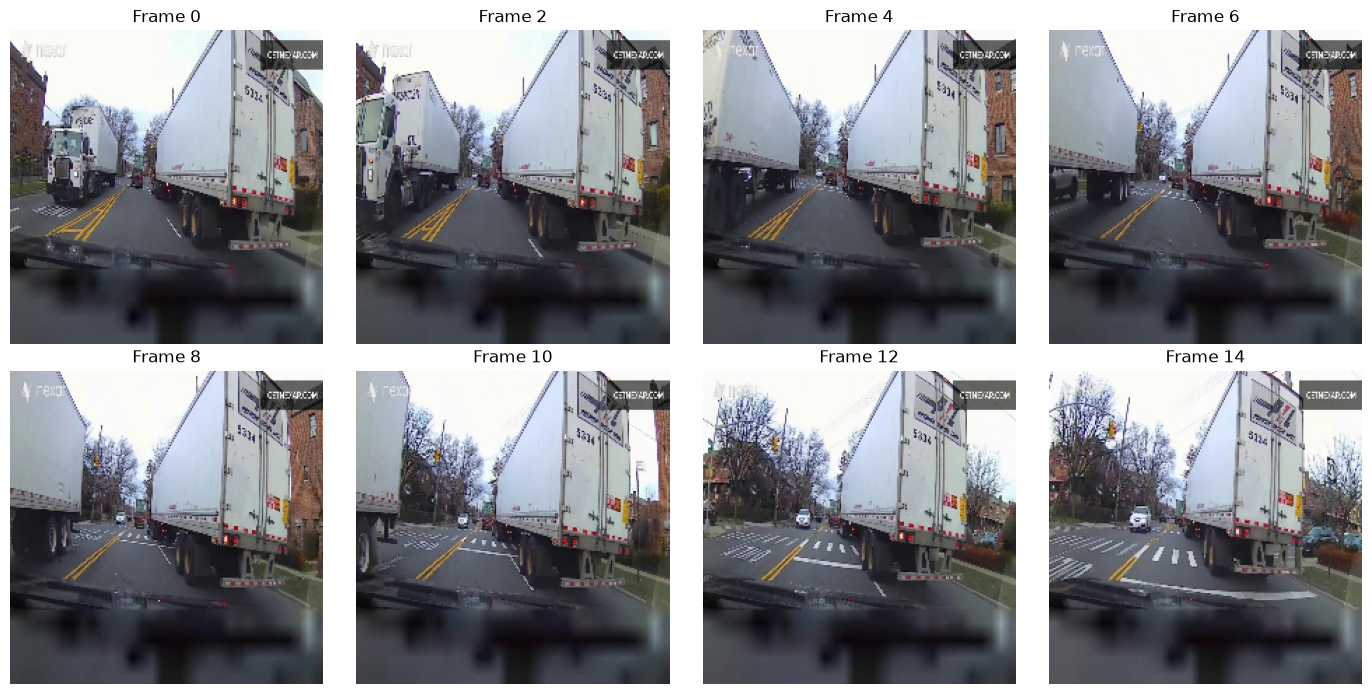

In [10]:

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    frame_index = i * 2
    ax.imshow(clip[frame_index])
    ax.set_title(f"Frame {frame_index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:

# random sampling negative videos 
OUTPUT_DIR = Path("nexar_data/processed_frames_randomnegetive")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLIP_SECONDS = 4.0
WARNING_SECONDS = 1.0
NUM_FRAMES = 16
IMAGE_SIZE = (224, 224)

rng = random.Random(42)
results = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    video_path = Path(str(row["video_file"]))
    video_id = str(row["video_id"])
    label = int(row["label"])

    record = {
        "video_id": video_id,
        "label": label,
        "status": None,
        "clip_path": None,
        "reason": None,
        "video_duration": None,
        "start_time": None,
        "end_time": None,
        "padded_seconds": None,
    }

    try:
        # Read video information
        cap = cv2.VideoCapture(str(video_path))
        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        cap.release()

        if fps <= 0 or total_frames <= 0:
            raise ValueError("Invalid FPS or frame count")

        duration = total_frames / fps
        record["video_duration"] = duration

        if duration < CLIP_SECONDS:
            raise ValueError("Video is shorter than 4 seconds")

        # POSITIVE: clip ends 1 second before the crash.
        if label == 1:
            if pd.isna(row["time_of_event"]):
                raise ValueError("Positive sample has no time_of_event")

            event_time = float(row["time_of_event"])
            start_time = event_time - WARNING_SECONDS - CLIP_SECONDS
            end_time = event_time - WARNING_SECONDS

            # Do not silently clamp the start to zero.
            if start_time < 0 or end_time > duration:
                raise ValueError("Insufficient footage for pre-crash clip")

            # Extractor computes end = crash_time - WARNING_SECONDS.
            target_time = event_time

        # NEGATIVE: randomly sample a 4-second window.
        else:
            start_time = rng.uniform(0.0, duration - CLIP_SECONDS)
            end_time = start_time + CLIP_SECONDS

            # Extractor computes end = target_time - WARNING_SECONDS.
            target_time = end_time + WARNING_SECONDS

        clip_path = OUTPUT_DIR / f"{video_id}.npy"

        # Re-extract clips; do not reuse clips from the old strategy.
        if clip_path.exists():
            clip_path.unlink()

        clip, info = extract_pre_crash_clip(
            video_path=video_path,
            crash_time=target_time,
            output_path=clip_path,
            clip_seconds=CLIP_SECONDS,
            warning_seconds=WARNING_SECONDS,
            num_frames=NUM_FRAMES,
            image_size=IMAGE_SIZE,
            short_clip="skip",
        )

        record["status"] = info["status"]
        record["reason"] = info.get("reason")
        record["start_time"] = info.get("start_time")
        record["end_time"] = info.get("end_time")
        record["padded_seconds"] = info.get("padded_seconds", 0)

        if clip is not None:
            record["clip_path"] = str(clip_path)

    except Exception as e:
        record["status"] = "error"
        record["reason"] = str(e)

    results.append(record)

    if len(results) % 100 == 0:
        pd.DataFrame(results).to_csv(
            OUTPUT_DIR / "processing_log.csv",
            index=False
        )

processed_df = pd.DataFrame(results)
processed_df.to_csv(
    OUTPUT_DIR / "processing_log.csv",
    index=False
)

print("\nProcessing status:")
print(processed_df["status"].value_counts(dropna=False))

print("\nSuccessful clips by class:")
print(
    processed_df[processed_df["status"] == "ok"]
    .groupby("label")
    .size()
)

print("\nSkipped/error samples by class:")
print(
    processed_df[processed_df["status"].isin(["skipped", "error"])]
    .groupby(["label", "status"])
    .size()
)


100%|██████████| 1500/1500 [1:04:09<00:00,  2.57s/it]


Processing status:
status
ok       1498
error       2
Name: count, dtype: int64

Successful clips by class:
label
0    750
1    748
dtype: int64

Skipped/error samples by class:
label  status
1      error     2
dtype: int64


In [12]:

log_path = "nexar_data/processed_frames_randomnegetive/processing_log.csv"
data = pd.read_csv(log_path)

data = data[data["status"].isin(["ok", "ok_existing"])].copy()
data = data.dropna(subset=["clip_path", "label"])
data["label"] = data["label"].astype(int)

train_df, temp_df = train_test_split(data , test_size=0.30 , random_state=42 , stratify=data["label"])
val_df, test_df = train_test_split(temp_df , test_size=0.50 , random_state=42 , stratify=temp_df["label"])

train_df.to_csv("nexar_data/train.csv", index=False)
val_df.to_csv("nexar_data/val.csv", index=False)
test_df.to_csv("nexar_data/test.csv", index=False)

for name, part in [("Train", train_df) , ("Validation", val_df) , ("Test", test_df)]:
    print(f"\n{name}: {len(part)} videos")
    print(part["label"].value_counts().sort_index())


Train: 1048 videos
label
0    525
1    523
Name: count, dtype: int64

Validation: 225 videos
label
0    112
1    113
Name: count, dtype: int64

Test: 225 videos
label
0    113
1    112
Name: count, dtype: int64


In [ ]:
# augmentation function — train only

BRIGHTNESS_RANGE = (0.80, 1.20)
GAMMA_RANGE = (0.80, 1.30)
CONTRAST_RANGE = (0.85, 1.15)
NOISE_STD_RANGE = (0.01, 0.03)
NOISE_PROBABILITY = 0.50


def augment_video(frames):
    if frames.ndim != 4 or frames.shape[0] != 3:
        raise ValueError(f"Expected [3,T,H,W], got {tuple(frames.shape)}")
    if not frames.is_floating_point():
        raise TypeError("Convert uint8 frames to float in [0,1] before augmentation")

    # Each parameter is sampled ONCE and shared by all video frames.
    brightness = random.uniform(*BRIGHTNESS_RANGE)
    gamma = random.uniform(*GAMMA_RANGE)
    contrast = random.uniform(*CONTRAST_RANGE)

    frames = (frames * brightness).clamp(0.0, 1.0)
    frames = frames.pow(gamma)

    # Per-channel mean over the entire video for contrast adjustment.
    mean = frames.mean(dim=(1, 2, 3), keepdim=True)
    frames = ((frames - mean) * contrast + mean).clamp(0.0, 1.0)

    if random.random() < NOISE_PROBABILITY:
        sigma = random.uniform(*NOISE_STD_RANGE)
        # Independent per-pixel/frame noise mimics sensor noise.
        frames = (frames + torch.randn_like(frames) * sigma).clamp(0.0, 1.0)

    return frames

sample = torch.rand(3, 16, 224, 224)
augmented = augment_video(sample)
assert augmented.shape == sample.shape
assert augmented.min() >= 0 and augmented.max() <= 1
print("Augmentation function OK:", tuple(augmented.shape))


Augmentation function OK: (3, 16, 224, 224)


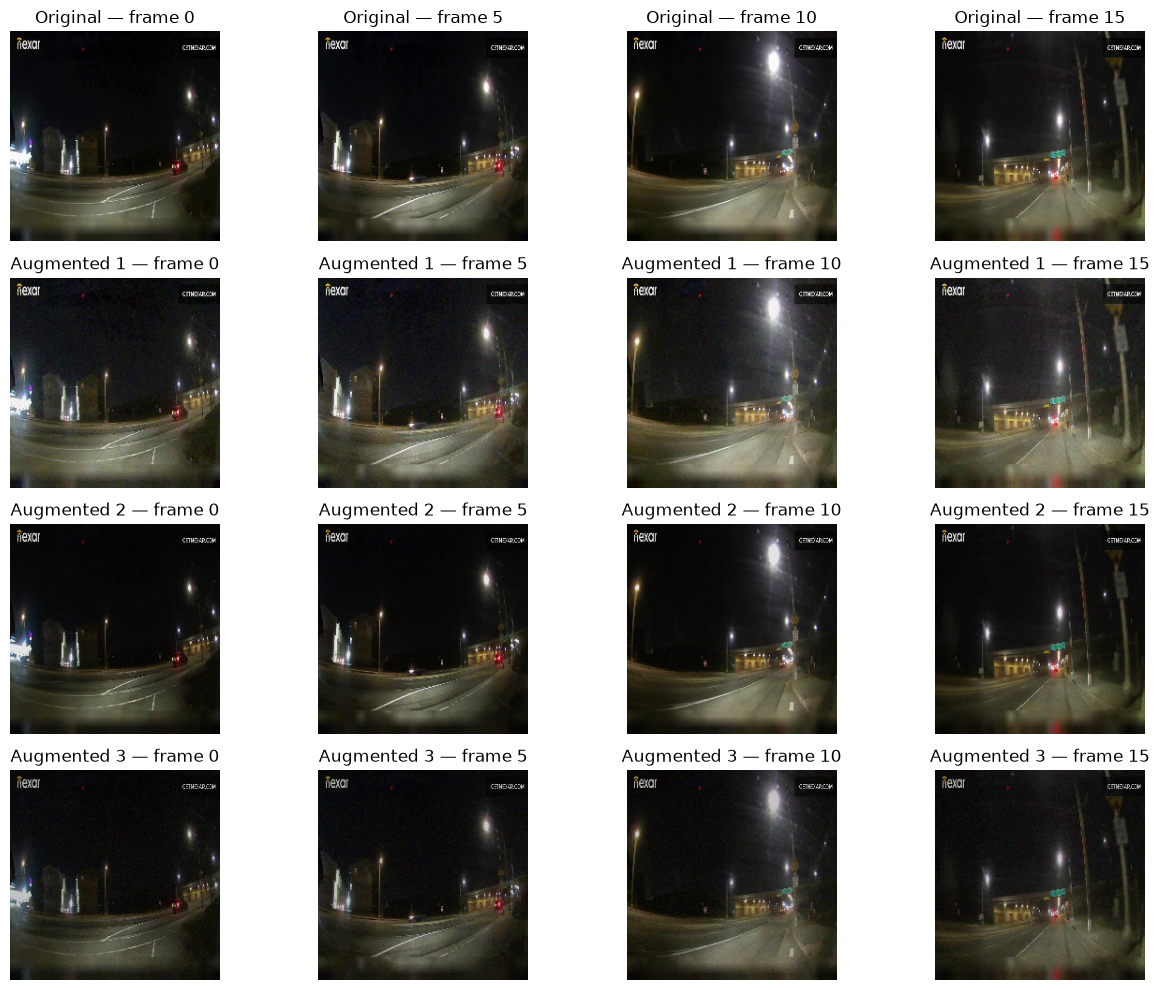

Original clip shape: (3, 16, 224, 224)
Original range: 0.0 1.0


In [ ]:
if len(train_df) == 0:
    raise ValueError("train_df is empty")

clip_file = Path(str(train_df.iloc[0]["clip_path"]))
if not clip_file.exists():
    raise FileNotFoundError(f"Clip not found: {clip_file}. Run frame extraction first.")

raw_clip = np.load(clip_file)  # expected [T,H,W,3] uint8 RGB
assert raw_clip.ndim == 4 and raw_clip.shape[-1] == 3, raw_clip.shape
frames_01 = torch.from_numpy(raw_clip.copy()).permute(3, 0, 1, 2).float() / 255.0

random.seed(42)
torch.manual_seed(42)
views = [frames_01] + [augment_video(frames_01) for _ in range(3)]
frame_ids = np.linspace(0, frames_01.shape[1]-1, 4, dtype=int)
fig, axes = plt.subplots(4, 4, figsize=(13, 10))
for row, (name, clip) in enumerate(zip(["Original", "Augmented 1", "Augmented 2", "Augmented 3"], views)):
    for col, t in enumerate(frame_ids):
        axes[row, col].imshow(clip[:, int(t)].permute(1, 2, 0).numpy())
        axes[row, col].set_title(f"{name} — frame {int(t)}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

print("Original clip shape:", tuple(frames_01.shape))
print("Original range:", float(frames_01.min()), float(frames_01.max()))


In [ ]:
class NexarDataset(Dataset):
    def __init__(self, dataframe, augment=False, views_per_video=1):
        self.data = dataframe.reset_index(drop=True)
        self.augment = bool(augment)
        self.views_per_video = int(views_per_video)
        if self.views_per_video < 1:
            raise ValueError("views_per_video must be >= 1")
        if not self.augment and self.views_per_video != 1:
            raise ValueError("Multiple views should only be enabled for training")

    def __len__(self):
        return len(self.data) * self.views_per_video

    def __getitem__(self, idx):
        video_idx = idx // self.views_per_video
        view_idx = idx % self.views_per_video
        row = self.data.iloc[video_idx]
        frames = np.load(row["clip_path"])

        # [T,H,W,C] uint8 RGB -> [C,T,H,W] float [0,1]
        frames = torch.from_numpy(frames.copy())
        frames = frames.permute(3, 0, 1, 2).float() / 255.0

        if self.augment and (self.views_per_video == 1 or view_idx > 0):
            frames = augment_video(frames)

        mean = torch.tensor([0.45, 0.45, 0.45]).view(3, 1, 1, 1)
        std = torch.tensor([0.225, 0.225, 0.225]).view(3, 1, 1, 1)
        frames = (frames - mean) / std
        label = torch.tensor(int(row["label"]), dtype=torch.long)
        return frames, label


TRAIN_VIEWS = 1 # badan agar khoroji ha drost bodan bayad taghir bedim be 4

train_dataset = NexarDataset(train_df, augment=True, views_per_video=TRAIN_VIEWS)
val_dataset = NexarDataset(val_df, augment=False)
test_dataset = NexarDataset(test_df, augment=False)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

videos, labels = next(iter(train_loader))
print("Train views:", TRAIN_VIEWS)
print("Dataset sizes:", len(train_dataset), len(val_dataset), len(test_dataset))
print("Video batch:", tuple(videos.shape), "Labels:", labels.tolist())
assert videos.ndim == 5 and videos.shape[1:]==(3,16,224,224)


Train views: 1
Dataset sizes: 1048 225 225
Video batch: (4, 3, 16, 224, 224) Labels: [0, 0, 1, 0]


In [16]:


print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

weights = MViT_V2_S_Weights.DEFAULT
print(weights.transforms())

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
CUDA available: False
VideoClassification(
    crop_size=[224, 224]
    resize_size=[256]
    mean=[0.45, 0.45, 0.45]
    std=[0.225, 0.225, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [17]:


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = MViT_V2_S_Weights.DEFAULT
model = mvit_v2_s(weights=weights)


in_features = model.head[1].in_features
model.head[1] = nn.Linear(in_features, 2)
model = model.to(device)

print("Device:", device)
print("Classifier:", model.head)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/mvit_v2_s-ae3be167.pth" to C:\Users\User/.cache\torch\hub\checkpoints\mvit_v2_s-ae3be167.pth


100%|██████████| 132M/132M [00:41<00:00, 3.35MB/s] 

Device: cpu
Classifier: Sequential(
  (0): Dropout(p=0.5, inplace=True)
  (1): Linear(in_features=768, out_features=2, bias=True)
)
Parameters: 34,231,682


In [18]:

class NexarCollisionModel(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()

        weights = MViT_V2_S_Weights.DEFAULT if pretrained else None
        self.backbone = mvit_v2_s(weights=weights)
        in_features = self.backbone.head[1].in_features
        self.backbone.head[1] = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.backbone(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = NexarCollisionModel(num_classes=2, pretrained=True).to(device)

print(model)

NexarCollisionModel(
  (backbone): MViT(
    (conv_proj): Conv3d(3, 96, kernel_size=(3, 7, 7), stride=(2, 4, 4), padding=(1, 3, 3))
    (pos_encoding): PositionalEncoding()
    (blocks): ModuleList(
      (0): MultiscaleBlock(
        (norm1): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
        (attn): MultiscaleAttention(
          (qkv): Linear(in_features=96, out_features=288, bias=True)
          (project): Sequential(
            (0): Linear(in_features=96, out_features=96, bias=True)
          )
          (pool_q): Pool(
            (pool): Conv3d(96, 96, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), groups=96, bias=False)
            (norm_act): Sequential(
              (0): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
            )
          )
          (pool_k): Pool(
            (pool): Conv3d(96, 96, kernel_size=(3, 3, 3), stride=(1, 8, 8), p

In [19]:


criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters() , lr=1e-4 , weight_decay=1e-3)
scheduler = ReduceLROnPlateau(optimizer , mode="max" , factor=0.5 , patience=1 , min_lr=1e-7)
scaler = torch.amp.GradScaler("cuda" , enabled=(device.type == "cuda"))
checkpoint_path = Path("nexar_data/best_mvit_collision_aug.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)


In [ ]:
num_epochs = 15
patience = 4

best_val_f1 = -1.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(num_epochs):

    # training
    model.train()
    train_loss_sum = 0.0
    train_count = 0
    train_preds = []
    train_targets = []

    for videos, labels in train_loader:
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type , dtype=torch.float16 , enabled=(device.type == "cuda")):
            outputs = model(videos)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

        predictions = outputs.argmax(dim=1)

        train_preds.extend(predictions.detach().cpu().tolist())
        train_targets.extend(labels.cpu().tolist())

    train_loss = train_loss_sum / train_count
    train_acc = accuracy_score(train_targets, train_preds)
    train_f1 = f1_score(train_targets, train_preds , average="macro", zero_division=0)


    # validation
    model.eval()

    val_loss_sum = 0.0
    val_count = 0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for videos, labels in val_loader:
            videos = videos.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type=device.type , dtype=torch.float16 , enabled=(device.type == "cuda")):
                outputs = model(videos)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_count += batch_size

            predictions = outputs.argmax(dim=1)

            val_preds.extend(predictions.cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    val_loss = val_loss_sum / val_count
    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(val_targets , val_preds , average="macro" , zero_division=0)
    val_precision = precision_score(val_targets , val_preds , average="macro" , zero_division=0)
    val_recall = recall_score(val_targets , val_preds , average="macro" , zero_division=0)

    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # updating learning rate 
    scheduler.step(val_f1)

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Train Macro F1: {train_f1:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    print(
        f"    Val Macro Precision: {val_precision:.4f} | "
        f"Val Macro Recall: {val_recall:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    # saveing best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_f1": best_val_f1,
                "class_names": ["no_collision", "collision"]
            },
            checkpoint_path
        )

        print(f"    Saved best model: {checkpoint_path}")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

print(f"\nBest validation macro F1: {best_val_f1:.4f}")
print(f"Checkpoint saved at: {checkpoint_path}")

In [ ]:


#### not completed yet / still working on this 
SEED = 42
TARGET_FPS = 6
IMAGE_SIZE = 112
NUM_CLASSES = 2
DATA_DIR = Path("nexar_data/videos")
VIDEO_CACHE = DATA_DIR / "videos_6fps_112"
VIDEO_CACHE.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = DATA_DIR / "best_long_mvit.pth"
BATCH_SIZE = 4
EPOCHS = 15
LEARNING_RATE_BACKBONE = 1e-5
LEARNING_RATE_HEAD = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:

def decode_video_at_fps(video_path , target_fps=6 , image_size=112 ):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    original_fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if original_fps <= 0 or total_frames <= 0:
        cap.release()
        raise ValueError("Invalid FPS or frame count")

    duration = total_frames / original_fps
    interval = original_fps / target_fps

    frames = []
    next_sample = 0
    frame_index = 0

    while True:
        success, frame = cap.read()

        if not success:
            break

        if frame_index >= round(next_sample):
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(
                frame,
                (image_size, image_size),
            )
            frames.append(frame)
            next_sample += interval

        frame_index += 1

    cap.release()

    if not frames:
        raise ValueError("No frames extracted")

    return np.stack(frames).astype(np.uint8), duration



records = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    video_id = str(row["video_id"])
    video_path = Path(str(row["video_file"]))
    label = int(row["label"])

    cache_path = VIDEO_CACHE / f"{video_id}.npy"

    try:
        frames, duration = decode_video_at_fps(
            video_path,
            target_fps=TARGET_FPS,
            image_size=IMAGE_SIZE,
        )

        np.save(cache_path, frames)

        group_id = str(
            row.get("source_video_path", video_id)
        )

        records.append({
            "video_id": video_id,
            "label": label,
            "group_id": group_id,
            "video_duration": duration,
            "num_frames": len(frames),
            "cache_path": str(cache_path),
            "status": "ok",
            "reason": None,
        })

    except Exception as exc:
        records.append({
            "video_id": video_id,
            "label": label,
            "group_id": str(
                row.get("source_video_path", video_id)
            ),
            "video_duration": None,
            "num_frames": None,
            "cache_path": None,
            "status": "error",
            "reason": str(exc),
        })

manifest = pd.DataFrame(records)
manifest.to_csv(DATA_DIR / "videos_6fps_manifest.csv", index=False)

print(manifest["status"].value_counts())
print("\nSuccessful samples per class:")
print(
    manifest[manifest["status"] == "ok"]
    .groupby("label").size()
)
